GT4Py - GridTools Framework

Copyright (c) 2014-2024, ETH Zurich
All rights reserved.

Please, refer to the LICENSE file in the root directory.
SPDX-License-Identifier: BSD-3-Clause

# Shallow Water Model

A doubly periodic shallow water model on an Arakawa C-grid, integrated with a leapfrog
scheme and a Robert-Asselin time filter, ported from the NCAR
[SWM](https://github.com/NCAR/SWM) mini-app, a long-standing benchmark for comparing
programming models.

The prognostic equations are

$$
\frac{\partial \mathbf{V}}{\partial t} + \zeta\,\mathbf{k} \times \mathbf{V}
  + \nabla\left(P + \tfrac{1}{2}\mathbf{V}\cdot\mathbf{V}\right) = 0,
\qquad
\frac{\partial P}{\partial t} + \nabla\cdot(P\mathbf{V}) = 0 ,
$$

without rotation (the Coriolis parameter $f$ is zero, as in NCAR/SWM), discretised with the potential-enstrophy-conserving finite differences of Sadourny (1975,
his Eq. 4). The four intermediates below are his mass fluxes and diagnostics,

$$
U = \overline{P}^{\,x} u, \qquad V = \overline{P}^{\,y} v, \qquad
H = P + \tfrac{1}{2}\left(\overline{u^2}^{\,x} + \overline{v^2}^{\,y}\right), \qquad
\eta = \frac{\delta_x v - \delta_y u}{\overline{P}^{\,xy}} ,
$$

named `cu`, `cv`, `h` and `z` here.

In [1]:
from typing import Any

import numpy as np

import gt4py.next as gtx
from gt4py.next import backend as next_backend, experimental as gtx_experimental
from gt4py._core import definitions as core_defs

import swm_numpy

## Grid and backend

Fields carry **one halo cell on every side**, so the domain runs from `-1` to `M+1`. All
three prognostic fields share this one index space; the C-grid staggering is expressed by
the shifts inside the operators rather than by different array shapes.

The backend that executes the field operator also allocates its fields. The compiled
`gtfn` and `dace` backends generate C++ or CUDA. The experimental embedded backends run the
Python of the field operator on the arrays of one library: `embedded_numpy`,
`embedded_cupy`, `embedded_jax` and `embedded_torch`. JAX and torch take a `device` to choose
between CPU and GPU; without one, JAX uses its default device and torch the CPU.

In [2]:
I = gtx.Dimension("I")
J = gtx.Dimension("J")

IJField = gtx.Field[gtx.Dims[I, J], gtx.float64]

M = swm_numpy.M  # 16
N = swm_numpy.N  # 16

DX = swm_numpy.DX  # 100 km
DY = swm_numpy.DY
DT = swm_numpy.DT  # 90 s
ALPHA = swm_numpy.ALPHA  # Robert-Asselin filter coefficient

### jax.jit and torch.compile

Embedded execution runs the Python of the field operator on every call. The experimental
backends `gtx_experimental.jax_jit` and `gtx_experimental.torch_compile` instead run it
once under `jax.jit` or `torch.compile`, on fields of JAX arrays or torch tensors, and call
the compiled function from then on. They write `out=` like any other backend.

A program is traced again for every new field domain, so each grid size compiles once. The
scalars are traced, so `tdt` and `alpha` changing after the first step do not compile
again.

### Choosing a backend

Uncomment one of the backends below.

In [3]:
CPU = core_defs.Device(core_defs.DeviceType.CPU, 0)
CUDA = core_defs.Device(core_defs.DeviceType.CUDA, 0)

backend, device = gtx_experimental.embedded_numpy, None
# backend, device = gtx.gtfn_cpu, None
# backend, device = gtx.gtfn_gpu, None
# backend, device = gtx.dace_cpu, None
# backend, device = gtx.dace_gpu, None
# backend, device = gtx_experimental.embedded_cupy, None
# backend, device = gtx_experimental.embedded_jax, CPU
# backend, device = gtx_experimental.embedded_jax, CUDA
# backend, device = gtx_experimental.jax_jit, CPU
# backend, device = gtx_experimental.jax_jit, CUDA
# backend, device = gtx_experimental.embedded_torch, CPU
# backend, device = gtx_experimental.embedded_torch, CUDA
# backend, device = gtx_experimental.torch_compile, CUDA

## Differential operators

Each operator comes in two variants that differ only in shift direction. The forward form
($+1$) maps an unstaggered quantity onto a staggered location, the backward form ($-1$)
maps back. Which one a term needs is fixed by where its operands live: `p` and `h` sit at
cell centres, `u` and `cu` on $x$-faces, `v` and `cv` on $y$-faces, and `z` on corners.

Staggered dimensions would remove the need for the two shift directions, and operators
generic over the dimension would remove the separate $x$ and $y$ variants, which are features currently being worked on.

In [4]:
@gtx.field_operator
def avg_x(f: IJField) -> IJField:
    """Average onto the next x-face."""
    return 0.5 * (f(I + 1) + f)


@gtx.field_operator
def avg_y(f: IJField) -> IJField:
    """Average onto the next y-face."""
    return 0.5 * (f(J + 1) + f)


@gtx.field_operator
def avg_x_staggered(f: IJField) -> IJField:
    """Average an x-staggered field back onto cell centres."""
    return 0.5 * (f(I - 1) + f)


@gtx.field_operator
def avg_y_staggered(f: IJField) -> IJField:
    """Average a y-staggered field back onto cell centres."""
    return 0.5 * (f(J - 1) + f)


@gtx.field_operator
def delta_x(dx: gtx.float64, f: IJField) -> IJField:
    """Forward difference in x."""
    return (f(I + 1) - f) / dx


@gtx.field_operator
def delta_y(dy: gtx.float64, f: IJField) -> IJField:
    """Forward difference in y."""
    return (f(J + 1) - f) / dy


@gtx.field_operator
def delta_x_staggered(dx: gtx.float64, f: IJField) -> IJField:
    """Backward difference in x, for an x-staggered field."""
    return (f - f(I - 1)) / dx


@gtx.field_operator
def delta_y_staggered(dy: gtx.float64, f: IJField) -> IJField:
    """Backward difference in y, for a y-staggered field."""
    return (f - f(J - 1)) / dy

## The timestep

One fused field operator produces all six updated fields. The first three are the leapfrog
update of the prognostic variables; the last three are the time-filtered previous level,

$$ u^{\text{old}} \leftarrow u + \alpha\,(u^{\text{new}} - 2u + u^{\text{old}}) , $$

which suppresses the computational mode of the leapfrog scheme.

In [5]:
@gtx.field_operator
def timestep(
    u: IJField,
    v: IJField,
    p: IJField,
    uold: IJField,
    vold: IJField,
    pold: IJField,
    dx: gtx.float64,
    dy: gtx.float64,
    tdt: gtx.float64,
    alpha: gtx.float64,
) -> tuple[IJField, IJField, IJField, IJField, IJField, IJField]:
    """Advance one leapfrog step and return (unew, vnew, pnew, uold, vold, pold)."""
    cu = avg_x(p) * u
    cv = avg_y(p) * v
    z = (delta_x(dx, v) - delta_y(dy, u)) / avg_x(avg_y(p))
    h = p + 0.5 * (avg_x_staggered(u * u) + avg_y_staggered(v * v))

    unew = uold + avg_y_staggered(z) * avg_y_staggered(avg_x(cv)) * tdt - delta_x(dx, h) * tdt
    vnew = vold - avg_x_staggered(z) * avg_x_staggered(avg_y(cu)) * tdt - delta_y(dy, h) * tdt
    pnew = pold - delta_x_staggered(dx, cu) * tdt - delta_y_staggered(dy, cv) * tdt

    uold_new = u + alpha * (unew - 2.0 * u + uold)
    vold_new = v + alpha * (vnew - 2.0 * v + vold)
    pold_new = p + alpha * (pnew - 2.0 * p + pold)

    return unew, vnew, pnew, uold_new, vold_new, pold_new

## Periodicity

The domain wraps in both directions. Here the halo is refreshed **outside** the field
operator, after each step: the operator computes the interior only, and the halo is then
overwritten with the opposite edge by assigning to the field. Field assignment works for
every array library, including JAX, whose arrays are immutable and get a new buffer.

Rows are copied before columns, which is what fills the corners correctly.

In [6]:
def apply_periodic(field: gtx.Field, m: int = M, n: int = N) -> None:
    """Refresh the one-cell halo of `field` from the opposite edge."""

    def copy(dst: dict, src: dict) -> None:
        dst_domain = gtx.domain(dst)
        src_buffer = field[gtx.domain(src)].ndarray
        field[dst_domain] = type(field).from_array(src_buffer, domain=dst_domain)

    all_j = (-1, n + 1)
    copy({I: (-1, 0), J: all_j}, {I: (m - 1, m), J: all_j})
    copy({I: (m, m + 1), J: all_j}, {I: (0, 1), J: all_j})
    all_i = (-1, m + 1)
    copy({I: all_i, J: (-1, 0)}, {I: all_i, J: (n - 1, n)})
    copy({I: all_i, J: (n, n + 1)}, {I: all_i, J: (0, 1)})

## Time loop

`uold`, `vold` and `pold` are updated in place and never swapped; only the prognostic
fields ping-pong with their `new` counterparts. The first cycle is a forward Euler step
with the filter switched off, which is how the leapfrog scheme is started.

A `Model` holds the fields of one integration and the field operator bound to its backend,
so that repeated calls of `advance` continue the same integration with the same compiled
or traced operator. The halo refresh runs outside the field operator.
`advance(..., periodic=False)` skips it: the results are wrong, but the steps then run back
to back without host work in between.

In [7]:
class Model:
    def __init__(
        self,
        m: int = M,
        n: int = N,
        *,
        backend: next_backend.Backend,
        device: core_defs.Device | None = None,
    ):
        self.m, self.n = m, n
        self.domain = gtx.domain({I: (-1, m + 1), J: (-1, n + 1)})
        self.interior = gtx.domain({I: (0, m), J: (0, n)})
        self.step = timestep.with_backend(backend)
        self.cycle = 0

        def as_halo_field(a: np.ndarray) -> gtx.Field:
            return gtx.as_field(
                self.domain, np.pad(a, 1, mode="wrap"), allocator=backend, device=device
            )

        u0, v0, p0 = swm_numpy.initial_conditions(m, n, DX, DY)
        self.u, self.v, self.p = as_halo_field(u0), as_halo_field(v0), as_halo_field(p0)
        self.uold, self.vold, self.pold = as_halo_field(u0), as_halo_field(v0), as_halo_field(p0)
        # A valid halo in every buffer keeps `p` nonzero there when the refresh is skipped.
        self.unew, self.vnew, self.pnew = as_halo_field(u0), as_halo_field(v0), as_halo_field(p0)

    def advance(self, cycles: int, periodic: bool = True) -> None:
        """Integrate `cycles` more steps."""
        for _ in range(cycles):
            tdt = DT if self.cycle == 0 else 2.0 * DT
            alpha = 0.0 if self.cycle == 0 else ALPHA

            self.step(
                self.u,
                self.v,
                self.p,
                self.uold,
                self.vold,
                self.pold,
                DX,
                DY,
                tdt,
                alpha,
                out=(self.unew, self.vnew, self.pnew, self.uold, self.vold, self.pold),
                domain=self.interior,
                offset_provider={},
            )

            if periodic:
                for field in (self.unew, self.vnew, self.pnew):
                    apply_periodic(field, self.m, self.n)

            self.u, self.unew = self.unew, self.u
            self.v, self.vnew = self.vnew, self.v
            self.p, self.pnew = self.pnew, self.p
            self.cycle += 1


def run(
    itmax: int,
    m: int = M,
    n: int = N,
    *,
    backend: next_backend.Backend,
    device: core_defs.Device | None = None,
) -> tuple[gtx.Field, gtx.Field, gtx.Field]:
    """Integrate `itmax` steps and return the final `u`, `v`, `p` fields."""
    model = Model(m, n, backend=backend, device=device)
    model.advance(itmax)
    return model.u, model.v, model.p


def interior_of(field: gtx.Field, m: int = M, n: int = N) -> np.ndarray:
    return field.asnumpy()[1 : m + 1, 1 : n + 1]

## Validation against NumPy

The companion module `swm_numpy.py` implements the same scheme with `numpy.roll`, which
gives periodicity for free and needs no halo at all. Agreement between the two is a check
that the halo bookkeeping here is right.

In [8]:
STEPS = 100

# Both implementations evaluate the same expressions, but compiled backends and the JIT
# compilers may reorder or fuse operations, so agreement is to rounding, not bit-for-bit.
# Tolerances are absolute because u and v cross zero.
ATOL_UV = 3e-12  # peak |u|, |v| ~ 4
ATOL_P = 1e-9  # peak |p| ~ 5e4


def test_matches_numpy(backend: next_backend.Backend, device: core_defs.Device | None = None):
    u, v, p = run(STEPS, backend=backend, device=device)
    u_ref, v_ref, p_ref = swm_numpy.run(STEPS)

    np.testing.assert_allclose(interior_of(u), u_ref, atol=ATOL_UV)
    np.testing.assert_allclose(interior_of(v), v_ref, atol=ATOL_UV)
    np.testing.assert_allclose(interior_of(p), p_ref, atol=ATOL_P)


test_matches_numpy(backend, device)
print("GT4Py and NumPy agree after", STEPS, "steps")

GT4Py and NumPy agree after 100 steps


## Validation against the NCAR reference

`swm_reference.npz` holds `u`, `v`, `p` after the full 4000-step benchmark, taken from
[NCAR/SWM](https://github.com/NCAR/SWM) `ref/16x16` (Apache-2.0). Reproducing it end to
end is the real correctness check.

In [9]:
def test_matches_reference(backend: next_backend.Backend, device: core_defs.Device | None = None):
    u, v, p = run(swm_numpy.ITMAX, backend=backend, device=device)
    u_out, v_out, p_out = swm_numpy.to_reference_layout(
        interior_of(u), interior_of(v), interior_of(p)
    )

    reference = np.load("swm_reference.npz")
    np.testing.assert_allclose(u_out, reference["u"], atol=ATOL_UV)
    np.testing.assert_allclose(v_out, reference["v"], atol=ATOL_UV)
    np.testing.assert_allclose(p_out, reference["p"], atol=ATOL_P)


test_matches_reference(backend, device)
print("GT4Py reproduces the NCAR reference after", swm_numpy.ITMAX, "steps")

GT4Py reproduces the NCAR reference after 4000 steps


## The flow

`u`, `v` and `p` after `STEPS` steps.

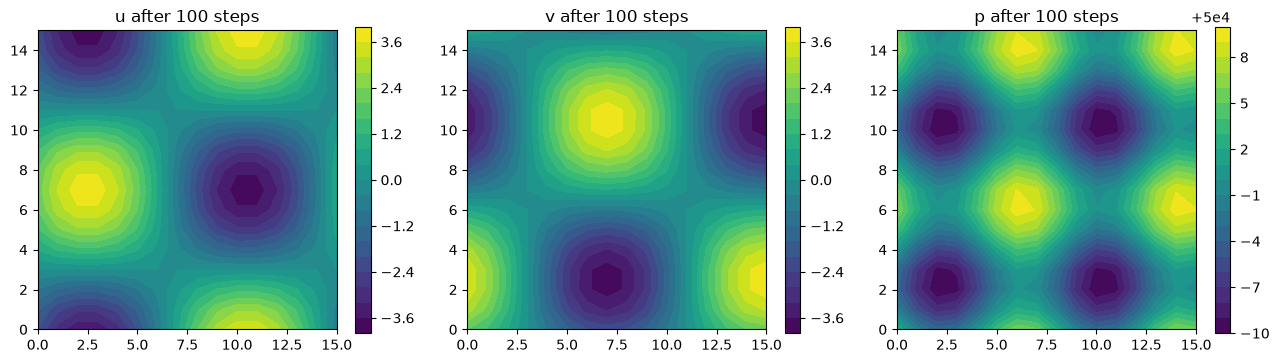

In [10]:
import matplotlib.pyplot as plt

u, v, p = run(STEPS, backend=backend, device=device)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, field, name in zip(axes, (u, v, p), ("u", "v", "p")):
    image = ax.contourf(interior_of(field).T, levels=20)
    ax.set_title(f"{name} after {STEPS} steps")
    ax.set_aspect("equal")
    fig.colorbar(image, ax=ax)
fig.tight_layout()

## Performance comparison

The same model on every backend installed here: the compiled `gtfn` and `dace` backends on
CPU and GPU, and embedded execution on NumPy, CuPy, JAX and torch arrays, eagerly and
under `jax.jit` and `torch.compile`. Each backend is first checked against the NumPy
implementation, then timed on a sweep of grid sizes.

The timed steps skip the halo refresh, which runs on the host between two steps. Their
results are therefore wrong, but the steps run back to back: GPU work is launched
asynchronously and the host's dispatch of the next step overlaps with the device's
execution of the previous one. This emulates real-world use cases: in more complex models the Python dispatch overhead is hidden even on smaller grids.

The first steps include compilation and the first leapfrog step uses different scalars, so
`WARMUP_STEPS` run before any timing; the first step is reported separately. Then
`REPEATS` blocks of `TIMED_STEPS` steps are timed, each between two waits for the device,
and the median time per step over the blocks is reported. The comparison takes minutes, so
it is opt-in. Start the kernel with `PYTHONOPTIMIZE=1` to time without GT4Py's runtime
checks.

In [11]:
import importlib.util
import json
import statistics
import time

RUN_PERFORMANCE_COMPARISON = False

GRID_SIZES = (64, 256, 1024, 2048, 4096)
WARMUP_STEPS = 5
TIMED_STEPS = 20
REPEATS = 5


def installed(module: str) -> bool:
    return importlib.util.find_spec(module) is not None


def comparison_backends() -> dict[str, tuple[next_backend.Backend, core_defs.Device | None]]:
    """Every backend whose libraries and devices are available here, with its device."""
    try:
        import cupy

        gpu = cupy.cuda.runtime.getDeviceCount() > 0
    except (ImportError, RuntimeError):
        gpu = False

    backends = {"dace_cpu": (gtx.dace_cpu, None)}
    if gpu:
        backends["dace_gpu"] = (gtx.dace_gpu, None)
    backends["gtfn_cpu"] = (gtx.gtfn_cpu, None)
    if gpu:
        backends["gtfn_gpu"] = (gtx.gtfn_gpu, None)
    backends["numpy"] = (gtx_experimental.embedded_numpy, None)
    if gpu:
        backends["cupy"] = (gtx_experimental.embedded_cupy, None)
    if installed("jax"):
        import jax

        device = CUDA if jax.default_backend() == "gpu" else CPU
        label = "cuda" if device is CUDA else "cpu"
        backends[f"jax [{label}]"] = (gtx_experimental.embedded_jax, device)
        backends[f"jax.jit [{label}]"] = (gtx_experimental.jax_jit, device)
    if installed("torch"):
        import torch

        device = CUDA if torch.cuda.is_available() else None
        label = "cuda" if device else "cpu"
        backends[f"torch [{label}]"] = (gtx_experimental.embedded_torch, device)
        backends[f"torch.compile [{label}]"] = (gtx_experimental.torch_compile, device)
    return backends


def wait(model: Model) -> None:
    """Block until the device has finished every step launched so far."""
    for field in (model.u, model.v, model.p, model.uold, model.vold, model.pold):
        buffer = field.ndarray
        library = type(buffer).__module__.split(".")[0]
        if hasattr(buffer, "block_until_ready"):
            buffer.block_until_ready()
        elif library == "cupy":
            buffer.device.synchronize()
        elif library == "torch" and buffer.is_cuda:
            import torch

            torch.cuda.synchronize(buffer.device)


def time_steps(
    size: int, backend: next_backend.Backend, device: core_defs.Device | None
) -> dict[str, Any]:
    """Return the time of the first step and the time per step of each timed block."""
    model = Model(size, size, backend=backend, device=device)

    start = time.perf_counter()
    model.advance(1, periodic=False)
    wait(model)
    first_step = time.perf_counter() - start
    model.advance(WARMUP_STEPS - 1, periodic=False)

    per_step = []
    for _ in range(REPEATS):
        wait(model)
        start = time.perf_counter()
        model.advance(TIMED_STEPS, periodic=False)
        wait(model)
        per_step.append((time.perf_counter() - start) / TIMED_STEPS)

    if not all(np.isfinite(field.asnumpy()).all() for field in (model.u, model.v, model.p)):
        raise FloatingPointError("non-finite fields after the timed steps")
    return {"first_step": first_step, "per_step": per_step}


def compare(grid_sizes=GRID_SIZES) -> dict[str, dict[int, dict[str, Any]]]:
    """Validate every backend, then time it on every grid size."""
    timings = {}
    for name, (comparison_backend, comparison_device) in comparison_backends().items():
        test_matches_numpy(comparison_backend, comparison_device)
        timings[name] = {}
        for size in grid_sizes:
            timings[name][size] = time_steps(size, comparison_backend, comparison_device)
            median = 1e3 * statistics.median(timings[name][size]["per_step"])
            print(f"{name:24} {size:5}^2  {median:10.3f} ms/step", flush=True)
    return timings


def report(timings: dict[str, dict[int, dict[str, Any]]]) -> None:
    sizes = list(next(iter(timings.values())))
    header = "".join(f"{f'{size}^2':>12}" for size in sizes)
    print(f"{'median ms/step':24}{header}    {'first step [s]':>16}")
    for name, by_size in timings.items():
        steady = "".join(
            f"{1e3 * statistics.median(result['per_step']):12.3f}" for result in by_size.values()
        )
        first = "/".join(f"{result['first_step']:.2f}" for result in by_size.values())
        print(f"{name:24}{steady}    {first:>16}")

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, by_size in timings.items():
        points = [size * size for size in by_size]
        medians = [1e3 * statistics.median(result["per_step"]) for result in by_size.values()]
        ax.loglog(points, medians, marker="o", label=name)
    ax.set_xlabel("grid points")
    ax.set_ylabel("median time per step [ms]")
    ax.legend(fontsize="small")
    fig.tight_layout()


if RUN_PERFORMANCE_COMPARISON:
    timings = compare()
    with open("swm_timings.json", "w") as file:
        json.dump(timings, file)
    report(timings)

## References

Sadourny, R. (1975). The dynamics of finite-difference models of the shallow-water
equations. *Journal of the Atmospheric Sciences*, 32(4), 680-689.
[doi:10.1175/1520-0469(1975)032&lt;0680:TDOFDM&gt;2.0.CO;2](https://doi.org/10.1175/1520-0469(1975)032%3C0680:TDOFDM%3E2.0.CO;2)

The benchmark itself --- its configuration, initial condition and reference data --- is
[NCAR/SWM](https://github.com/NCAR/SWM), which implements the same model across a range of
languages and programming models.